# Which of 590 sensors actually predict yield failure?

Analysis of the [UCI SECOM](https://archive.ics.uci.edu/dataset/179/secom) dataset: 1,567 wafers, 590 anonymized in-line sensor features, pass/fail at test (Jul–Oct 2008).

**Questions addressed**
1. Predict yield loss from sensor data (class imbalance).
2. Narrow 590 signals to a short list worth monitoring.
3. Flag abnormal wafers without relying on sort labels (anomaly detection).
4. Identify process regimes linked to higher fail rates (clustering).


## 0. Setup


In [1]:
import os
import time
import urllib.request
import warnings
from pathlib import Path

# Parallel worker processes don't inherit warnings.filterwarnings, only environment variables.
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning,ignore::FutureWarning"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import (HistGradientBoostingClassifier, IsolationForest,
                              RandomForestClassifier)
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
PASS_COLOR, FAIL_COLOR = "#4C72B0", "#C44E52"

## 1. Load the data

`secom.data` is a space-separated matrix (1,567 rows × 590 columns, `NaN` = missing).
`secom_labels.data` has the label (`-1` = pass, `1` = fail) and a timestamp. We recode the target to **1 = fail**, because the
"positive" class in classification should be the rare event we care about.

Sensor names are anonymized, so we name them `S000`–`S589` (0-indexed column position).


In [2]:
BASE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/secom/"
for fname in ["secom.data", "secom_labels.data", "secom.names"]:
    if not (DATA_DIR / fname).exists():
        print(f"Downloading {fname} ...")
        urllib.request.urlretrieve(BASE_URL + fname, DATA_DIR / fname)

X = pd.read_csv(DATA_DIR / "secom.data", sep=" ", header=None)
X.columns = [f"S{i:03d}" for i in range(X.shape[1])]

labels = pd.read_csv(DATA_DIR / "secom_labels.data", sep=" ", header=None,
                     names=["label", "timestamp"])
y = (labels["label"] == 1).astype(int).rename("fail")
timestamp = pd.to_datetime(labels["timestamp"], format="%d/%m/%Y %H:%M:%S")

print(f"Sensor matrix: {X.shape[0]:,} wafers x {X.shape[1]} sensors")
print(f"Date range:    {timestamp.min():%Y-%m-%d} to {timestamp.max():%Y-%m-%d}")
X.iloc[:5, :8]

Sensor matrix: 1,567 wafers x 590 sensors
Date range:    2008-07-19 to 2008-10-17


,S000,S001,S002,S003,S004,S005,S006,S007
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235


## 2. Exploratory data analysis: what makes this dataset hard?

useless. With imbalanced data we must use metrics that focus on the rare class (precision, recall, PR-AUC), covered in Section 4.

(constant, zero information), and many measure nearly the same physical quantity (highly correlated / redundant).


In [3]:
missing_frac = X.isna().mean()
n_unique = X.nunique()

print(f"Fails: {y.sum()} of {len(y):,} wafers ({y.mean():.1%})")
print(f"Accuracy of 'always predict PASS': {1 - y.mean():.1%}  <- the accuracy paradox\n")

pd.Series({
    "Share of all readings that are missing": f"{X.isna().mean().mean():.1%}",
    "Sensors with at least one missing value": int((missing_frac > 0).sum()),
    "Sensors missing in > 50% of wafers": int((missing_frac > 0.5).sum()),
    "Constant sensors (single unique value)": int((n_unique <= 1).sum()),
}).to_frame("value")

Fails: 104 of 1,567 wafers (6.6%)
Accuracy of 'always predict PASS': 93.4%  <- the accuracy paradox



,value
Share of all readings that are missing,4.5%
Sensors with at least one missing value,538
Sensors missing in > 50% of wafers,28
Constant sensors (single unique value),116


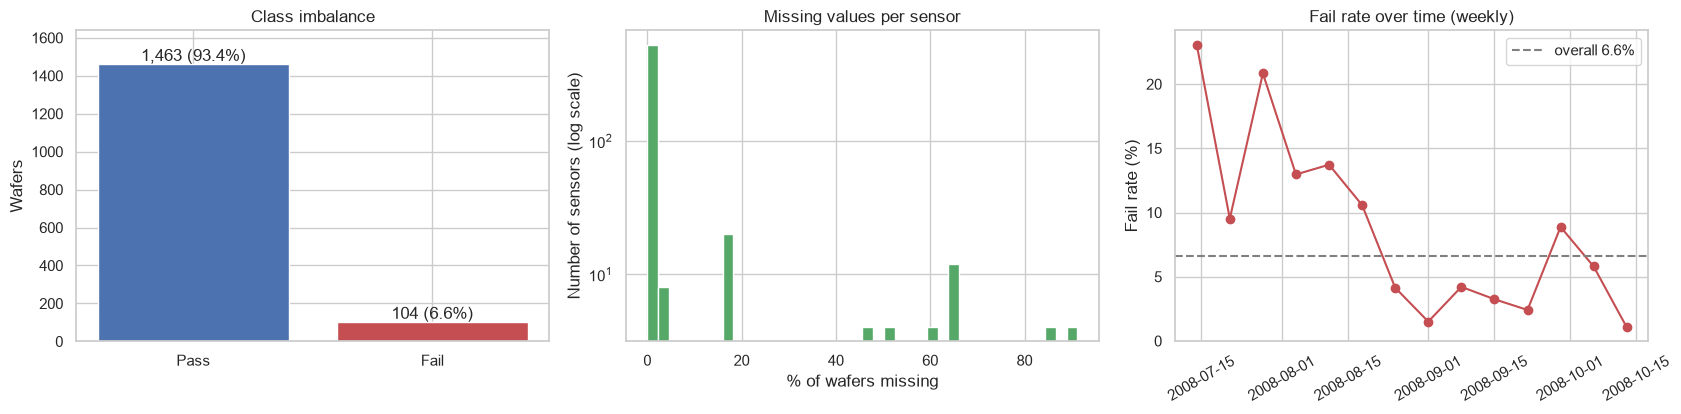

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))

counts = y.map({0: "Pass", 1: "Fail"}).value_counts()
axes[0].bar(counts.index, counts.values, color=[PASS_COLOR, FAIL_COLOR])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 15, f"{v:,} ({v / len(y):.1%})", ha="center")
axes[0].set(title="Class imbalance", ylabel="Wafers", ylim=(0, counts.max() * 1.12))

axes[1].hist(missing_frac * 100, bins=40, color="#55A868")
axes[1].set(title="Missing values per sensor", xlabel="% of wafers missing",
            ylabel="Number of sensors (log scale)", yscale="log")

weekly = y.groupby(timestamp.dt.to_period("W").dt.start_time).agg(["mean", "size"])
axes[2].plot(weekly.index, weekly["mean"] * 100, marker="o", color=FAIL_COLOR)
axes[2].axhline(y.mean() * 100, ls="--", color="gray", label=f"overall {y.mean():.1%}")
axes[2].set(title="Fail rate over time (weekly)", ylabel="Fail rate (%)")
axes[2].tick_params(axis="x", rotation=30)
axes[2].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "01_eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** the target is heavily imbalanced, a few dozen sensors are mostly empty, over a hundred are constant, and the fail
rate is **not stable over time** (it is much higher in the first weeks). That last point hints at process drift, which we revisit with
clustering in Section 7.


## 3. Train/test split and a leak-free cleaning pipeline

scaling) must be learned **only from the training set** and then *applied* to the test set. If you impute or select features on
the full dataset first, information from the test set leaks into training and your reported performance is too optimistic.

The safe pattern:
1. Split first (stratified, so train and test both have ~6.6% fails).
2. Wrap every preprocessing step in a scikit-learn **transformer** with `fit` (learn from train) and `transform` (apply anywhere).
3. Put the transformer inside a `Pipeline`, so cross-validation re-fits it within each fold automatically.

Our `SecomCleaner` transformer:
- drops sensors with > 50% missing values,
- imputes remaining gaps with the **median** (robust to outliers, which sensor data has plenty of),
- drops constant sensors,
- drops one of every pair of sensors with |correlation| > 0.95 (redundant signals).


In [5]:
X_train, X_test, y_train, y_test, ts_train, ts_test = train_test_split(
    X, y, timestamp, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {len(y_train):,} wafers, {y_train.sum()} fails ({y_train.mean():.1%})")
print(f"Test:  {len(y_test):,} wafers, {y_test.sum()} fails ({y_test.mean():.1%})")

Train: 1,175 wafers, 78 fails (6.6%)
Test:  392 wafers, 26 fails (6.6%)


In [6]:
class SecomCleaner(BaseEstimator, TransformerMixin):
    # Drop sparse / constant / redundant sensors and median-impute, learning everything from fit data only.

    def __init__(self, max_missing=0.5, corr_threshold=0.95):
        self.max_missing = max_missing
        self.corr_threshold = corr_threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        n_start = X.shape[1]

        cols = X.columns[X.isna().mean() <= self.max_missing]
        n_after_missing = len(cols)

        medians = X[cols].median()
        X_imp = X[cols].fillna(medians)
        cols = cols[X_imp.std().to_numpy() > 1e-8]
        n_after_constant = len(cols)

        corr = np.abs(np.corrcoef(X_imp[cols].to_numpy(), rowvar=False))
        redundant = (np.triu(corr, k=1) > self.corr_threshold).any(axis=0)
        cols = cols[~redundant]

        self.columns_ = cols
        self.medians_ = medians[cols]
        self.report_ = {
            "start": n_start,
            "dropped: > 50% missing": n_start - n_after_missing,
            "dropped: constant": n_after_missing - n_after_constant,
            "dropped: redundant (|r| > 0.95)": n_after_constant - len(cols),
            "kept": len(cols),
        }
        return self

    def transform(self, X):
        return pd.DataFrame(X)[self.columns_].fillna(self.medians_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_)


cleaner = SecomCleaner().fit(X_train)
Xtr = cleaner.transform(X_train)
Xte = cleaner.transform(X_test)
pd.Series(cleaner.report_).to_frame("sensors")

,sensors
start,590
dropped: > 50% missing,24
dropped: constant,116
dropped: redundant (|r| > 0.95),181
kept,269


**Result:** roughly half of the 590 sensors are removed before any modelling, purely on data-quality grounds. This alone is a useful
message for a fab: many logged signals carry no unique information.


## 4. Imbalanced classification: can we predict failures?

- **Recall** (sensitivity): of all true fails, what fraction did we catch?
- **Precision**: of the wafers we flagged, what fraction actually failed?
- **ROC-AUC**: probability the model ranks a random fail above a random pass. 0.5 = random, 1.0 = perfect. It can look good even
  when precision is poor, because it is dominated by the large pass class.
- **PR-AUC** (average precision): area under the precision-recall curve. **Random baseline = fail rate (~0.066)**, not 0.5.
  This is the most honest single number for rare-event detection.

- **Class weights** (`class_weight="balanced"`): errors on fails cost ~14× more in the loss function. Simple and usually effective.
- **SMOTE**: creates synthetic fail wafers by interpolating between real ones. Must be applied **inside** the CV fold (only on training
  data), which is why we use `imblearn.pipeline.Pipeline`.

5-fold CV repeated twice gives 10 estimates; we report mean ± standard deviation and choose the model by CV, **never by the test set**.


In [7]:
def make_models():
    return {
        "Logistic Regression (L2, class weights)": Pipeline([
            ("clean", SecomCleaner()), ("scale", StandardScaler()),
            ("model", LogisticRegression(C=0.05, class_weight="balanced", max_iter=5000))]),
        "Logistic Regression (L1 / Lasso, class weights)": Pipeline([
            ("clean", SecomCleaner()), ("scale", StandardScaler()),
            ("model", LogisticRegression(C=0.1, l1_ratio=1.0, solver="liblinear",
                                         class_weight="balanced"))]),
        "SMOTE + Logistic Regression": ImbPipeline([
            ("clean", SecomCleaner()), ("scale", StandardScaler()),
            ("smote", SMOTE(random_state=RANDOM_STATE)),
            ("model", LogisticRegression(C=0.05, max_iter=5000))]),
        "Random Forest (class weights)": Pipeline([
            ("clean", SecomCleaner()),
            ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                             class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=RANDOM_STATE))]),
        "Gradient Boosting (class weights)": Pipeline([
            ("clean", SecomCleaner()),
            ("model", HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                                     class_weight="balanced",
                                                     random_state=RANDOM_STATE))]),
    }


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
rows = []
for name, model in make_models().items():
    t0 = time.time()
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring={"roc": "roc_auc", "pr": "average_precision"})
    rows.append({"model": name,
                 "CV ROC-AUC": f"{s['test_roc'].mean():.3f} ± {s['test_roc'].std():.3f}",
                 "CV PR-AUC": f"{s['test_pr'].mean():.3f} ± {s['test_pr'].std():.3f}",
                 "_pr": s["test_pr"].mean(), "seconds": round(time.time() - t0, 1)})

cv_results = pd.DataFrame(rows).set_index("model").sort_values("_pr", ascending=False)
print(f"Random-guess PR-AUC baseline = fail rate = {y_train.mean():.3f}")
cv_results.drop(columns="_pr")

Random-guess PR-AUC baseline = fail rate = 0.066


,CV ROC-AUC,CV PR-AUC,seconds
model,,,
Random Forest (class weights),0.733 ± 0.045,0.208 ± 0.066,37.1
"Logistic Regression (L1 / Lasso, class weights)",0.682 ± 0.054,0.185 ± 0.046,11.2
"Logistic Regression (L2, class weights)",0.653 ± 0.051,0.162 ± 0.040,11.1
SMOTE + Logistic Regression,0.641 ± 0.055,0.158 ± 0.045,8.4
Gradient Boosting (class weights),0.664 ± 0.052,0.154 ± 0.046,686.0


Now fit every model on the full training set and evaluate **once** on the untouched test set.


In [8]:
fitted, test_proba = {}, {}
for name, model in make_models().items():
    fitted[name] = model.fit(X_train, y_train)
    test_proba[name] = model.predict_proba(X_test)[:, 1]

test_results = pd.DataFrame({
    name: {"Test ROC-AUC": roc_auc_score(y_test, p), "Test PR-AUC": average_precision_score(y_test, p)}
    for name, p in test_proba.items()}).T.loc[cv_results.index].round(3)
test_results

,Test ROC-AUC,Test PR-AUC
model,,
Random Forest (class weights),0.835,0.280
"Logistic Regression (L1 / Lasso, class weights)",0.694,0.159
"Logistic Regression (L2, class weights)",0.682,0.139
SMOTE + Logistic Regression,0.675,0.127
Gradient Boosting (class weights),0.735,0.214


In [9]:
best_name = cv_results.index[0]
p_best = test_proba[best_name]

rng = np.random.default_rng(RANDOM_STATE)
boot_roc, boot_pr = [], []
yt = y_test.to_numpy()
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0:
        continue
    boot_roc.append(roc_auc_score(yt[idx], p_best[idx]))
    boot_pr.append(average_precision_score(yt[idx], p_best[idx]))

print(f"Best model by CV: {best_name}")
print(f"Test ROC-AUC = {roc_auc_score(y_test, p_best):.3f}  "
      f"(95% bootstrap CI {np.percentile(boot_roc, 2.5):.3f} to {np.percentile(boot_roc, 97.5):.3f})")
print(f"Test PR-AUC  = {average_precision_score(y_test, p_best):.3f}  "
      f"(95% bootstrap CI {np.percentile(boot_pr, 2.5):.3f} to {np.percentile(boot_pr, 97.5):.3f})"
      f"  vs random {y_test.mean():.3f}")

Best model by CV: Random Forest (class weights)
Test ROC-AUC = 0.835  (95% bootstrap CI 0.758 to 0.902)
Test PR-AUC  = 0.280  (95% bootstrap CI 0.161 to 0.444)  vs random 0.066


test set with replacement 2,000 times shows the range of plausible values. **Always report uncertainty on small test sets.**


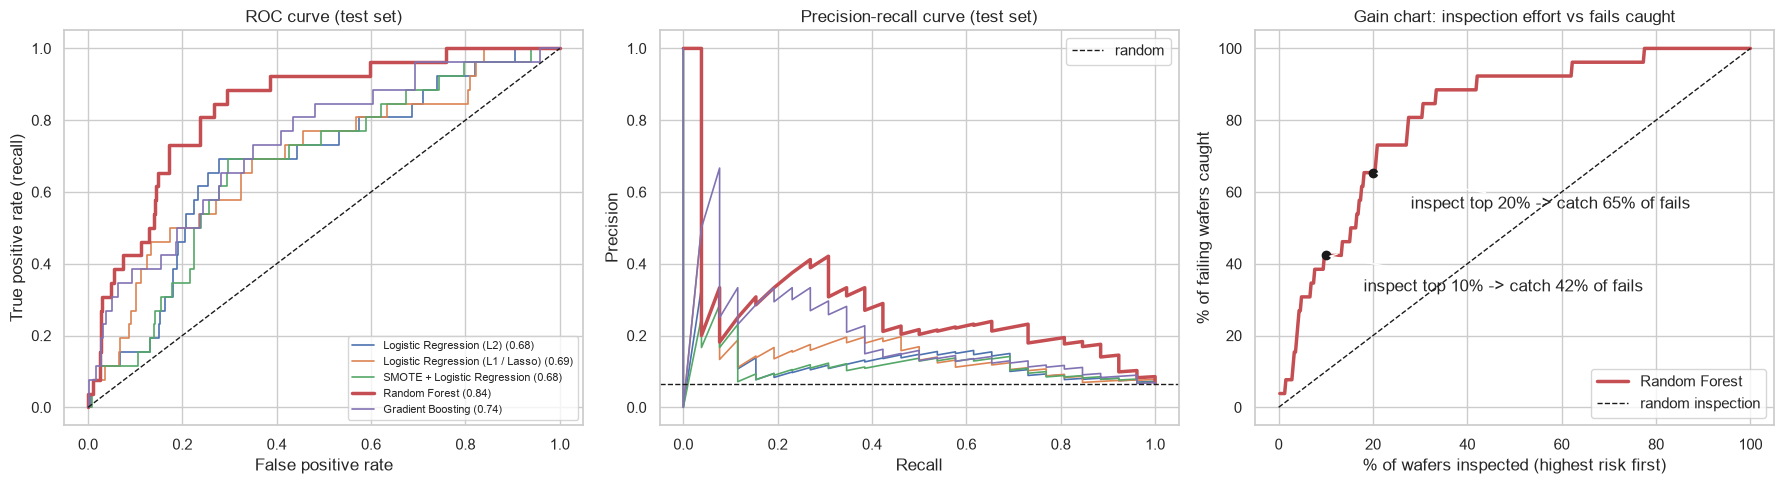

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    short = name.replace(" (class weights)", "").replace(", class weights", "")
    axes[0].plot(fpr, tpr, label=f"{short} ({roc_auc_score(y_test, p):.2f})",
                 lw=2.5 if name == best_name else 1.2)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, lw=2.5 if name == best_name else 1.2)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate (recall)")
axes[0].legend(fontsize=8, loc="lower right")
axes[1].axhline(y_test.mean(), ls="--", color="k", lw=1, label="random")
axes[1].set(title="Precision-recall curve (test set)", xlabel="Recall", ylabel="Precision")
axes[1].legend()

order = np.argsort(-p_best)
inspected = np.arange(1, len(order) + 1) / len(order)
caught = np.cumsum(yt[order]) / yt.sum()
axes[2].plot(inspected * 100, caught * 100, color=FAIL_COLOR, lw=2.5, label=best_name.split(" (")[0])
axes[2].plot([0, 100], [0, 100], "k--", lw=1, label="random inspection")
for frac in (0.10, 0.20):
    c = caught[int(frac * len(order)) - 1]
    axes[2].scatter(frac * 100, c * 100, color="k", zorder=3)
    axes[2].annotate(f"inspect top {frac:.0%} -> catch {c:.0%} of fails", (frac * 100, c * 100),
                     xytext=(frac * 100 + 8, c * 100 - 10), arrowprops=dict(arrowstyle="->"))
axes[2].set(title="Gain chart: inspection effort vs fails caught", xlabel="% of wafers inspected (highest risk first)",
            ylabel="% of failing wafers caught")
axes[2].legend(loc="lower right")

plt.tight_layout()
fig.savefig(FIG_DIR / "02_classification_performance.png", dpi=150, bbox_inches="tight")
plt.show()

answers the question a fab manager actually asks: *"If we can only send X% of wafers for extra inspection, what share of failures do
we catch?"* Below we pick a threshold that catches about half of the fails and show the confusion matrix.


In [11]:
prec, rec, thr = precision_recall_curve(y_test, p_best)
i = np.argmin(np.abs(rec[:-1] - 0.5))
threshold = thr[i]
pred = (p_best >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print(f"Threshold = {threshold:.3f}")
print(f"Flagged {tp + fp} of {len(pred)} wafers ({(tp + fp) / len(pred):.0%})")
print(f"Caught {tp} of {tp + fn} fails (recall {tp / (tp + fn):.0%}), precision {tp / (tp + fp):.0%} "
      f"(vs {y_test.mean():.0%} if flagged at random)")
pd.DataFrame([[tn, fp], [fn, tp]], index=["Actual pass", "Actual fail"],
             columns=["Predicted pass", "Predicted fail"])

Threshold = 0.133
Flagged 64 of 392 wafers (16%)
Caught 13 of 26 fails (recall 50%), precision 20% (vs 7% if flagged at random)


,Predicted pass,Predicted fail
Actual pass,315,51
Actual fail,13,13


timestamp, test on the last 25%). Performance usually drops; why is that the more realistic estimate for a production model?


## 5. Feature selection: which sensors actually matter?

| Family | Idea | Used here |
|---|---|---|
| **Filter** | Score each feature on its own, independent of any model | Mutual information |
| **Embedded** | The model selects features while training | L1 (Lasso) logistic regression; Random Forest impurity importance |
| **Model-agnostic / post-hoc** | Measure how much performance drops when a feature is scrambled | Permutation importance |

unstable: re-run on slightly different data and the top-10 changes. **Stability selection** fixes this: fit the model on 50 bootstrap
resamples and count how often each sensor lands in the top 20. A sensor selected in 90% of resamples is a real signal; one selected in
10% is probably noise.

share credit. That's why we removed near-duplicates in Section 3 and why we compare several methods.


In [12]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=RANDOM_STATE).fit(Xtr, y_train)

lasso = Pipeline([("scale", StandardScaler()),
                  ("model", LogisticRegression(C=0.1, l1_ratio=1.0, solver="liblinear",
                                               class_weight="balanced"))]).fit(Xtr, y_train)

mi = mutual_info_classif(Xtr, y_train, random_state=RANDOM_STATE)

rf.set_params(n_jobs=1)
perm = permutation_importance(rf, Xte, y_test, scoring="average_precision", n_repeats=10,
                              random_state=RANDOM_STATE, n_jobs=-1)
rf.set_params(n_jobs=-1)

B, TOP = 50, 20
boot_rng = np.random.default_rng(RANDOM_STATE)
selected_count = pd.Series(0, index=Xtr.columns)
for b in range(B):
    idx = boot_rng.integers(0, len(Xtr), len(Xtr))
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample",
                               n_jobs=-1, random_state=b).fit(Xtr.iloc[idx], y_train.iloc[idx])
    selected_count[pd.Series(m.feature_importances_, index=Xtr.columns).nlargest(TOP).index] += 1

importance = pd.DataFrame({
    "stability": selected_count / B,
    "rf_impurity": rf.feature_importances_,
    "lasso_abs_coef": np.abs(lasso.named_steps["model"].coef_[0]),
    "mutual_info": mi,
    "permutation": perm.importances_mean,
}, index=Xtr.columns)

methods = ["rf_impurity", "lasso_abs_coef", "mutual_info", "permutation"]
ranks = importance[methods].rank(ascending=False)
importance["methods_top20"] = (ranks <= TOP).sum(axis=1)
importance["mean_rank"] = ranks.mean(axis=1)
importance = importance.sort_values(["stability", "mean_rank"], ascending=[False, True])

print(f"Computed 5 importance views in {time.time() - t0:.0f}s")
print(f"Lasso kept {int((importance['lasso_abs_coef'] > 0).sum())} of {len(importance)} sensors (others coefficient = 0)")
importance.head(15).round(3)

Computed 5 importance views in 236s
Lasso kept 105 of 269 sensors (others coefficient = 0)


,stability,rf_impurity,lasso_abs_coef,mutual_info,permutation,methods_top20,mean_rank
S059,0.92,0.022,0.728,0.002,0.041,3,39.250
S103,0.92,0.019,0.105,0.026,-0.005,2,81.250
S033,0.78,0.013,0.000,0.006,0.005,2,73.875
S064,0.62,0.011,0.454,0.010,-0.006,2,81.750
S247,0.58,0.014,0.009,0.014,0.008,2,35.750
S205,0.58,0.013,0.093,0.002,0.017,2,55.500
S130,0.56,0.010,0.033,0.024,0.009,3,26.750
S021,0.56,0.008,0.486,0.003,0.001,2,72.000
S510,0.54,0.007,0.053,0.018,0.003,2,40.750
S213,0.52,0.011,0.092,0.002,0.007,2,59.250


see how performance changes with *k*.

To keep this honest, the ranking must be learned **inside each CV fold** (nested selection). If we used the ranking from the full
training set, the validation folds would have influenced which features were picked, which is a subtle form of leakage.


In [13]:
t0 = time.time()
K_VALUES = [3, 5, 10, 20, 40, 80, 150]
cv_k = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
records = []
for fold, (tr, va) in enumerate(cv_k.split(X_train, y_train)):
    fold_cleaner = SecomCleaner().fit(X_train.iloc[tr])
    A, V = fold_cleaner.transform(X_train.iloc[tr]), fold_cleaner.transform(X_train.iloc[va])
    ya, yv = y_train.iloc[tr], y_train.iloc[va]
    ranker = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                    n_jobs=-1, random_state=fold).fit(A, ya)
    ranked = A.columns[np.argsort(-ranker.feature_importances_)]
    for k in K_VALUES + [len(ranked)]:
        cols = ranked[:k]
        m = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=fold).fit(A[cols], ya)
        p = m.predict_proba(V[cols])[:, 1]
        records.append({"k": k if k in K_VALUES else "all", "pr_auc": average_precision_score(yv, p),
                        "roc_auc": roc_auc_score(yv, p)})

topk = pd.DataFrame(records).groupby("k", sort=False).agg(["mean", "std"]).round(3)
n_all = len(Xtr.columns)
n_folds = cv_k.get_n_splits()

pr_mean = topk[("pr_auc", "mean")]
pr_se = topk[("pr_auc", "std")] / np.sqrt(n_folds)
best_k = pr_mean.idxmax()
k_1se = next(k for k in topk.index if pr_mean[k] >= pr_mean[best_k] - pr_se[best_k])
share_1se = pr_mean[k_1se] / pr_mean[best_k]

print(f"Nested top-k evaluation took {time.time() - t0:.0f}s ('all' = every cleaned sensor, ~{n_all})")
print(f"Best mean PR-AUC: k = {best_k} ({pr_mean[best_k]:.3f} ± {pr_se[best_k]:.3f} s.e.)")
print(f"One-standard-error rule -> smallest k within 1 s.e. of the best: k = {k_1se} "
      f"({pr_mean[k_1se]:.3f}, {share_1se:.0%} of the best)")
topk

Nested top-k evaluation took 266s ('all' = every cleaned sensor, ~269)
Best mean PR-AUC: k = all (0.204 ± 0.028 s.e.)
One-standard-error rule -> smallest k within 1 s.e. of the best: k = 40 (0.187, 92% of the best)


pr_auc        roc_auc       
      mean    std    mean    std
k                               
3    0.120  0.048   0.595  0.041
5    0.134  0.049   0.615  0.069
10   0.158  0.069   0.671  0.056
20   0.174  0.062   0.687  0.024
40   0.187  0.073   0.704  0.042
80   0.191  0.060   0.707  0.042
150  0.202  0.082   0.718  0.039
all  0.204  0.088   0.718  0.040

score is within one standard error of the best. Here it tells us how few sensors we can keep without a *statistically meaningful* loss.
Simpler models are easier to monitor, explain to engineers and maintain in production.


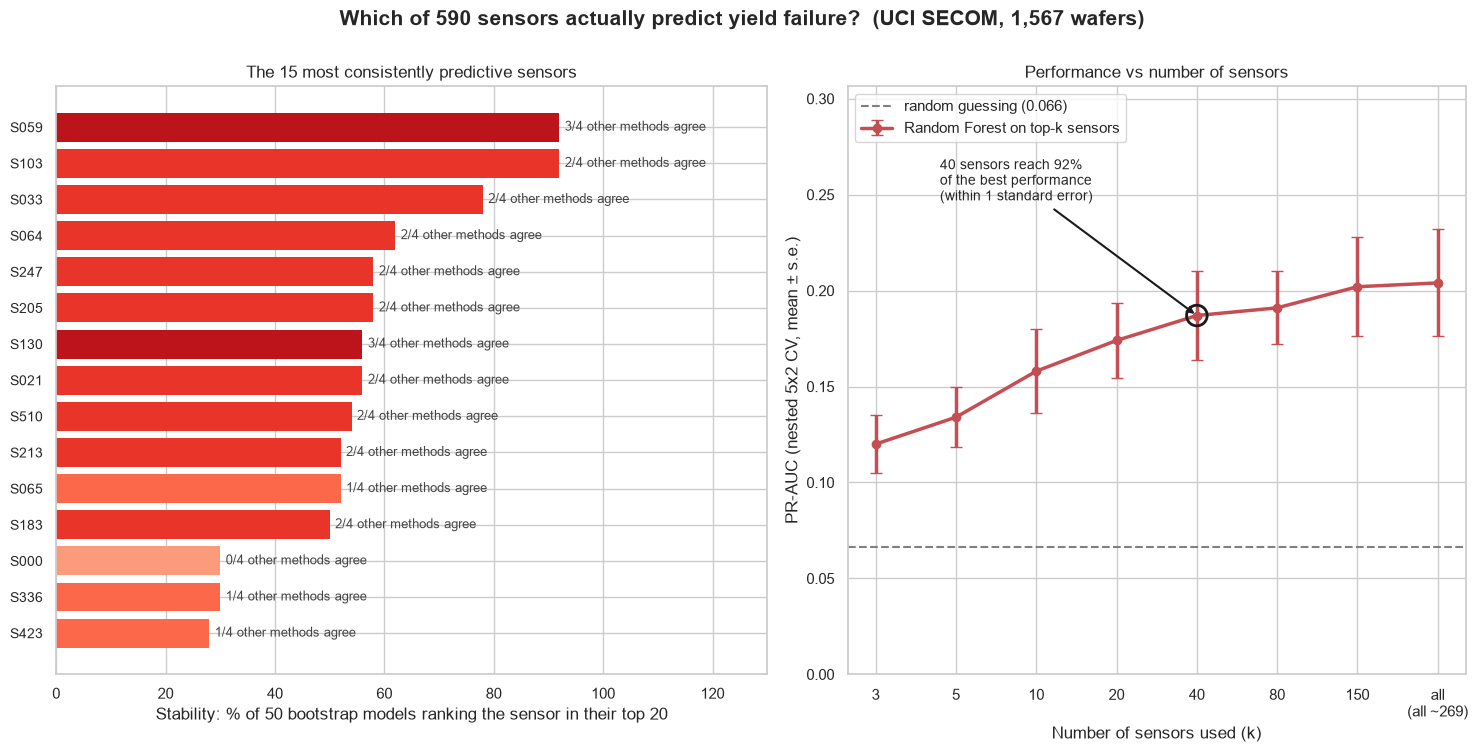

In [14]:
top_n = 15
top = importance.head(top_n).iloc[::-1]
topk_plot = topk.copy()
topk_plot.index = [str(i) for i in topk_plot.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), gridspec_kw={"width_ratios": [1.15, 1]})

colors = plt.cm.Reds(0.35 + 0.15 * top["methods_top20"].to_numpy())
bars = axes[0].barh(top.index, top["stability"] * 100, color=colors, edgecolor="none")
for bar, n in zip(bars, top["methods_top20"]):
    axes[0].text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                 f"{int(n)}/4 other methods agree", va="center", fontsize=9, color="#444")
axes[0].set(xlim=(0, 130), xlabel=f"Stability: % of {B} bootstrap models ranking the sensor in their top {TOP}",
            title=f"The {top_n} most consistently predictive sensors")
axes[0].tick_params(axis="y", labelsize=10)

x = np.arange(len(topk_plot))
means, stds = topk_plot[("pr_auc", "mean")], topk_plot[("pr_auc", "std")]
axes[1].errorbar(x, means, yerr=stds / np.sqrt(n_folds), marker="o", color=FAIL_COLOR, lw=2.5, capsize=4,
                 label="Random Forest on top-k sensors")
axes[1].axhline(y_train.mean(), ls="--", color="gray", label=f"random guessing ({y_train.mean():.3f})")
i_1se = list(topk_plot.index).index(str(k_1se))
axes[1].scatter(i_1se, means.iloc[i_1se], s=220, facecolors="none", edgecolors="k", lw=2, zorder=4)
axes[1].annotate(f"{k_1se} sensors reach {share_1se:.0%}\nof the best performance\n(within 1 standard error)",
                 (i_1se, means.iloc[i_1se]), xytext=(i_1se - 3.2, means.iloc[i_1se] + 0.06),
                 fontsize=10, arrowprops=dict(arrowstyle="->", color="k", lw=1.5))
axes[1].set_xticks(x, [f"{lbl}\n" + ("(all ~%d)" % n_all if lbl == "all" else "") for lbl in topk_plot.index])
axes[1].set(xlabel="Number of sensors used (k)", ylabel="PR-AUC (nested 5x2 CV, mean ± s.e.)",
            title="Performance vs number of sensors", ylim=(0, max(means + stds) * 1.05))
axes[1].legend(loc="upper left")

fig.suptitle("Which of 590 sensors actually predict yield failure?  (UCI SECOM, 1,567 wafers)",
             fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
fig.savefig(FIG_DIR / "linkedin_feature_importance.png", dpi=180, bbox_inches="tight")
plt.show()

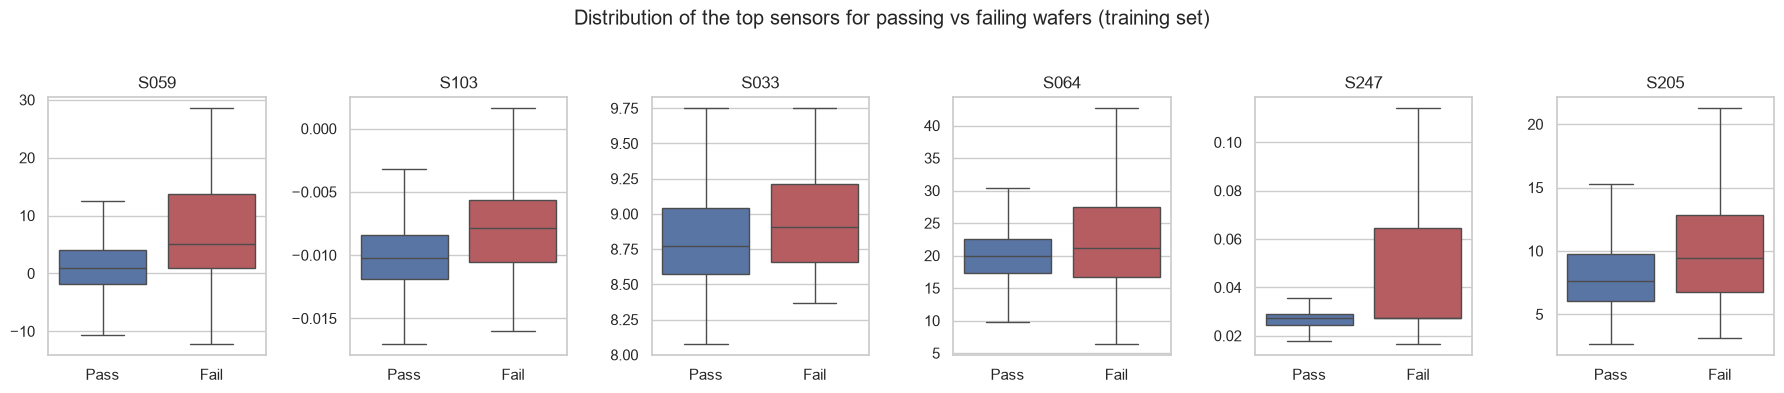

In [15]:
show = importance.index[:6]
plot_df = Xtr[show].assign(Outcome=y_train.map({0: "Pass", 1: "Fail"}).values)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.8))
for ax, col in zip(axes, show):
    sns.boxplot(data=plot_df, x="Outcome", y=col, hue="Outcome", order=["Pass", "Fail"],
                palette={"Pass": PASS_COLOR, "Fail": FAIL_COLOR}, showfliers=False, ax=ax, legend=False)
    ax.set(title=col, xlabel="", ylabel="")
fig.suptitle("Distribution of the top sensors for passing vs failing wafers (training set)", y=1.03)
plt.tight_layout()
fig.savefig(FIG_DIR / "03_top_sensor_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** a handful of sensors are selected in almost every bootstrap resample, and most of them are also ranked highly
by at least one other method. Performance climbs quickly over the first few dozen sensors and then flattens: the extra ~200 sensors add
only a small, statistically insignificant gain. For a process engineer, that short list is the actionable output: *these are the
parameters to put on an SPC chart first.*

Notice also that the methods **disagree** quite a bit (e.g., mutual information looks at each sensor alone, while the forest captures
interactions). That disagreement is exactly why stability selection plus a consensus view is more trustworthy than any single chart.

⚠️ **Important honesty point for interviews:** importance is *predictive association*, not *causation*. A sensor might rank highly
because it is downstream of the real root cause. Confirming root cause requires engineering knowledge or designed experiments (DOE).

Do the same sensors appear?


## 6. Anomaly detection: can we flag bad wafers *without* labels?

and new failure modes have no labelled history. **Anomaly detection** learns what *normal* looks like and flags anything unusual.

We train each detector on **passing training wafers only** (this setup is called *novelty detection*), then score the test set and check
how well "anomalous" lines up with "failed".

| Method | Intuition |
|---|---|
| **Isolation Forest** | Random splits isolate outliers in few steps; short average path length = anomaly |
| **Local Outlier Factor (LOF)** | Compares a point's local density with its neighbours'; much sparser than neighbours = anomaly |
| **PCA Hotelling T²** | Distance *within* the normal operating subspace (classic multivariate SPC in fabs) |
| **PCA SPE / Q-statistic** | Reconstruction error: how far a wafer lies *outside* the normal subspace (new kind of variation) |

Standardized values are clipped at ±10 so a single broken sensor reading cannot dominate distance-based scores.


In [16]:
pass_train = Xtr[y_train.values == 0]
scaler = StandardScaler().fit(pass_train)
A_norm = np.clip(scaler.transform(pass_train), -10, 10)
T_all = np.clip(scaler.transform(Xte), -10, 10)

iso = IsolationForest(n_estimators=500, random_state=RANDOM_STATE).fit(A_norm)
lof = LocalOutlierFactor(n_neighbors=35, novelty=True).fit(A_norm)
pca_mspc = PCA(n_components=0.90, random_state=RANDOM_STATE).fit(A_norm)
Z = pca_mspc.transform(T_all)

anomaly_scores = {
    "Isolation Forest": -iso.score_samples(T_all),
    "Local Outlier Factor": -lof.score_samples(T_all),
    f"PCA Hotelling T² ({pca_mspc.n_components_} PCs)": (Z ** 2 / pca_mspc.explained_variance_).sum(axis=1),
    "PCA SPE (reconstruction error)": ((T_all - pca_mspc.inverse_transform(Z)) ** 2).sum(axis=1),
}

def fails_caught_top(scores, frac=0.10):
    n = int(frac * len(scores))
    return yt[np.argsort(-scores)[:n]].sum() / yt.sum()

rows = {name: {"Test ROC-AUC": roc_auc_score(y_test, s), "Test PR-AUC": average_precision_score(y_test, s),
               "Fails caught in top 10% flagged": fails_caught_top(s)}
        for name, s in anomaly_scores.items()}
rows[f"(supervised) {best_name}"] = {"Test ROC-AUC": roc_auc_score(y_test, p_best),
                                     "Test PR-AUC": average_precision_score(y_test, p_best),
                                     "Fails caught in top 10% flagged": fails_caught_top(p_best)}
anomaly_results = pd.DataFrame(rows).T
anomaly_results.style.format({"Test ROC-AUC": "{:.3f}", "Test PR-AUC": "{:.3f}",
                              "Fails caught in top 10% flagged": "{:.0%}"})

,Test ROC-AUC,Test PR-AUC,Fails caught in top 10% flagged
Isolation Forest,0.646,0.160,27%
Local Outlier Factor,0.615,0.119,19%
PCA Hotelling T² (131 PCs),0.589,0.099,15%
PCA SPE (reconstruction error),0.605,0.107,12%
(supervised) Random Forest (class weights),0.835,0.280,42%


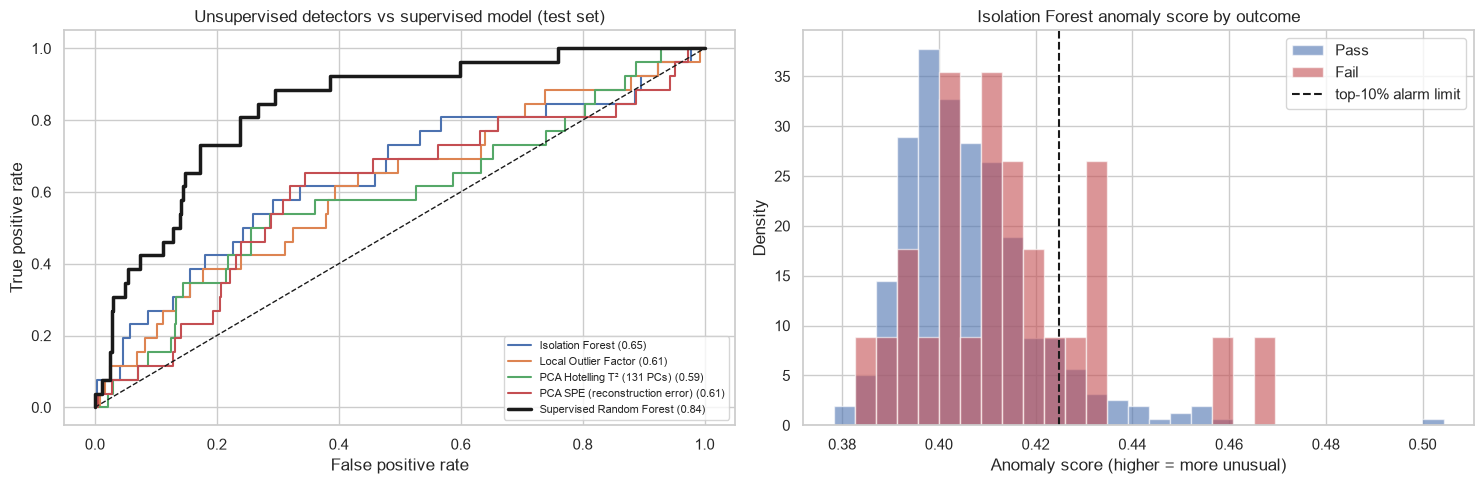

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, s in anomaly_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, s):.2f})")
fpr, tpr, _ = roc_curve(y_test, p_best)
axes[0].plot(fpr, tpr, "k", lw=2.5, label=f"Supervised {best_name.split(' (')[0]} ({roc_auc_score(y_test, p_best):.2f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="Unsupervised detectors vs supervised model (test set)", xlabel="False positive rate",
            ylabel="True positive rate")
axes[0].legend(fontsize=8, loc="lower right")

s = anomaly_scores["Isolation Forest"]
bins = np.linspace(s.min(), s.max(), 30)
axes[1].hist(s[yt == 0], bins=bins, alpha=0.6, color=PASS_COLOR, density=True, label="Pass")
axes[1].hist(s[yt == 1], bins=bins, alpha=0.6, color=FAIL_COLOR, density=True, label="Fail")
axes[1].axvline(np.percentile(s, 90), ls="--", color="k", label="top-10% alarm limit")
axes[1].set(title="Isolation Forest anomaly score by outcome", xlabel="Anomaly score (higher = more unusual)",
            ylabel="Density")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "04_anomaly_detection.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** unsupervised detectors do better than random at catching failures with **zero labels**, but they are clearly weaker than
the supervised model. The reason is that *anomalous ≠ defective*: many unusual wafers still pass, and some failures look normal on
most sensors. In practice, fabs use both: anomaly detection as an early-warning system for *new* excursions, and supervised models
for known failure modes once labels accumulate.

improve fail capture? (This is a nice example of combining supervised and unsupervised learning.)


## 7. Clustering: are there hidden process regimes?

1. **Standardize**, so sensors measured in different units contribute equally.
2. **Reduce dimension with PCA** (to 10 components). Distances in ~270 dimensions are dominated by noise (the *curse of dimensionality*).
3. **K-Means** groups wafers by similarity. Labels are **not** used to build the clusters, only afterwards to interpret them.
4. Choose *k* with the **silhouette score** (−1 to 1; higher = better separated) and the **elbow** in inertia.

fail rates differ across clusters more than chance would explain.

Clustering is purely unsupervised, so we use all wafers here.


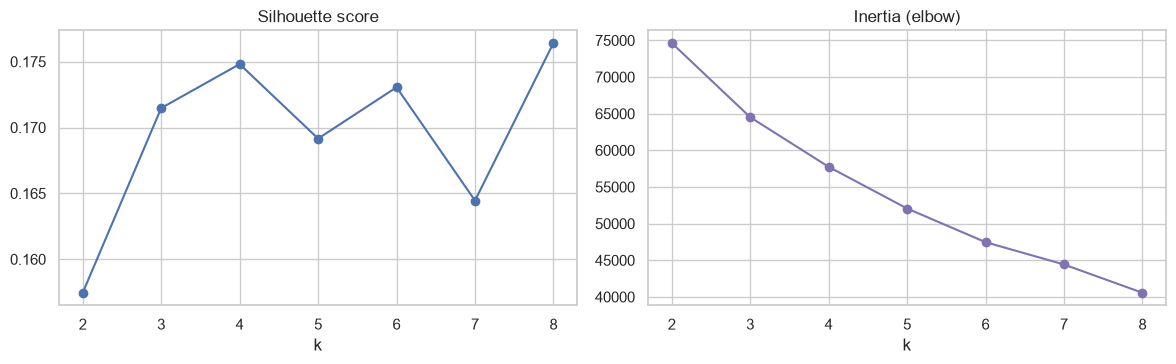

k,2,3,4,5,6,7,8
silhouette,0.157,0.171,0.175,0.169,0.173,0.164,0.176


In [18]:
all_clean = cleaner.transform(X)
Z_all = PCA(n_components=10, random_state=RANDOM_STATE).fit_transform(
    np.clip(StandardScaler().fit_transform(all_clean), -10, 10))

k_range = range(2, 9)
sil, inertia = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_all)
    sil.append(silhouette_score(Z_all, km.labels_))
    inertia.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(k_range), sil, marker="o"); axes[0].set(title="Silhouette score", xlabel="k")
axes[1].plot(list(k_range), inertia, marker="o", color="#8172B2"); axes[1].set(title="Inertia (elbow)", xlabel="k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(k_range), "silhouette": np.round(sil, 3)}).set_index("k").T

The silhouette scores are low and fairly flat, which tells us the wafers do **not** form sharply separated groups. That is normal for
process data, which varies continuously. When the metric does not pick a clear winner, choose a small *k* that is interpretable and
then check whether the clusters mean anything. We use **k = 4**.


In [19]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z_all)
cluster = pd.Series(km.labels_, name="cluster")

profile = pd.DataFrame({
    "wafers": cluster.value_counts().sort_index(),
    "fails": y.groupby(cluster).sum(),
    "fail_rate": y.groupby(cluster).mean(),
    "first_wafer": timestamp.groupby(cluster).min().dt.strftime("%Y-%m-%d"),
    "last_wafer": timestamp.groupby(cluster).max().dt.strftime("%Y-%m-%d"),
})
profile["lift_vs_overall"] = profile["fail_rate"] / y.mean()
chi2, p_value, dof, _ = chi2_contingency(pd.crosstab(cluster, y))
print(f"Chi-square test: chi2 = {chi2:.1f}, dof = {dof}, p-value = {p_value:.2g}")
profile.style.format({"fail_rate": "{:.1%}", "lift_vs_overall": "{:.2f}x"})

Chi-square test: chi2 = 22.2, dof = 3, p-value = 5.8e-05


,wafers,fails,fail_rate,first_wafer,last_wafer,lift_vs_overall
cluster,,,,,,
0,724,60,8.3%,2008-07-19,2008-10-16,1.25x
1,805,36,4.5%,2008-08-21,2008-10-17,0.67x
2,32,7,21.9%,2008-07-19,2008-09-12,3.30x
3,6,1,16.7%,2008-08-18,2008-10-11,2.51x


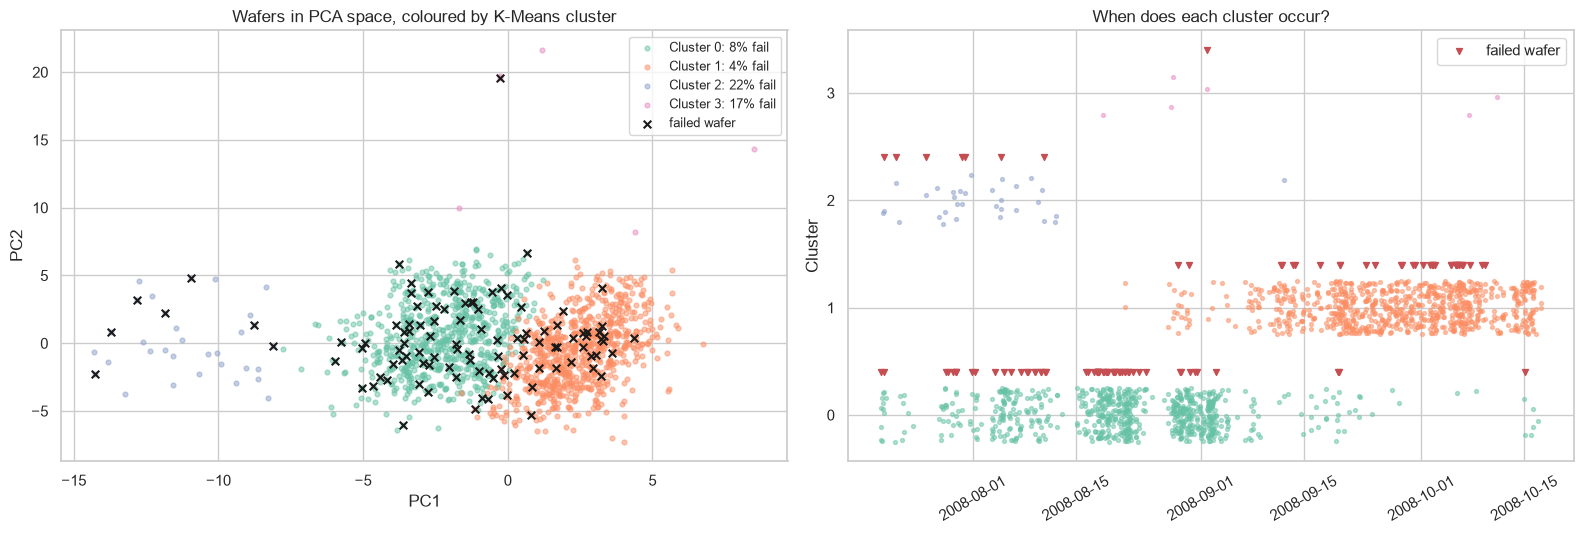

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
palette = sns.color_palette("Set2", K)

for c in range(K):
    m = (cluster == c).to_numpy()
    axes[0].scatter(Z_all[m, 0], Z_all[m, 1], s=12, alpha=0.5, color=palette[c],
                    label=f"Cluster {c}: {profile.loc[c, 'fail_rate']:.0%} fail")
fm = (y == 1).to_numpy()
axes[0].scatter(Z_all[fm, 0], Z_all[fm, 1], s=30, marker="x", color="k", label="failed wafer")
axes[0].set(title="Wafers in PCA space, coloured by K-Means cluster", xlabel="PC1", ylabel="PC2")
axes[0].legend(fontsize=9)

for c in range(K):
    m = (cluster == c).to_numpy()
    axes[1].scatter(timestamp[m], np.full(m.sum(), c) + np.random.default_rng(c).uniform(-0.25, 0.25, m.sum()),
                    s=8, alpha=0.5, color=palette[c])
axes[1].scatter(timestamp[fm], cluster[fm] + 0.4, marker="v", s=18, color=FAIL_COLOR, label="failed wafer")
axes[1].set(title="When does each cluster occur?", ylabel="Cluster", yticks=range(K))
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(loc="upper right")

plt.tight_layout()
fig.savefig(FIG_DIR / "05_clustering_regimes.png", dpi=150, bbox_inches="tight")
plt.show()

**Summary:** even without labels, clustering separates groups of wafers with very different fail rates, and the right panel
shows the clusters line up with calendar periods: the highest-fail cluster sits in the first weeks of the dataset, and the lowest-fail
cluster dominates from September onward, matching the fail-rate drop we saw in the EDA. The algorithm never saw the timestamps or the
labels, yet it rediscovered a process change. That pattern is typical of **process regimes**: a tool before/after
maintenance, a recipe change, or a drifting chamber. In a real fab you would take the high-fail cluster's dates to the equipment logs.


## 8. Summary


In [21]:
best_test = test_results.loc[best_name]
top10 = list(importance.index[:10])
hi = profile["fail_rate"].idxmax()
best_anom = anomaly_results.drop(index=f"(supervised) {best_name}")["Test ROC-AUC"].idxmax()
lo = profile["fail_rate"].idxmin()

print("KEY RESULTS")
print(f"- Data: {len(y):,} wafers, 590 sensors, {y.mean():.1%} fail rate; {cleaner.report_['kept']} sensors "
      f"survive data-quality cleaning")
print(f"- Best supervised model (chosen by CV): {best_name}")
print(f"    test ROC-AUC {best_test['Test ROC-AUC']:.2f}, PR-AUC {best_test['Test PR-AUC']:.2f} "
      f"({best_test['Test PR-AUC'] / y_test.mean():.1f}x the random baseline of {y_test.mean():.3f})")
print(f"    inspecting the top 10% riskiest wafers catches {fails_caught_top(p_best):.0%} of failures")
print(f"- Feature selection: {k_1se} sensors reach {share_1se:.0%} of the best nested-CV PR-AUC "
      f"({pr_mean[k_1se]:.3f} vs {pr_mean[best_k]:.3f} with k = {best_k}), within 1 standard error")
print(f"    most stable sensors: {', '.join(top10)}")
print(f"- Anomaly detection (no labels): best = {best_anom}, test ROC-AUC "
      f"{anomaly_results.loc[best_anom, 'Test ROC-AUC']:.2f}, catches "
      f"{anomaly_results.loc[best_anom, 'Fails caught in top 10% flagged']:.0%} of fails in its top 10% alarms")
print(f"- Clustering: fail rate differs across clusters (chi-square p = {p_value:.1g})")
for c in profile.sort_values("first_wafer").index:
    print(f"    cluster {c}: {profile.loc[c, 'wafers']:>4} wafers, fail rate {profile.loc[c, 'fail_rate']:5.1%} "
          f"({profile.loc[c, 'lift_vs_overall']:.1f}x), {profile.loc[c, 'first_wafer']} to {profile.loc[c, 'last_wafer']}")

KEY RESULTS
- Data: 1,567 wafers, 590 sensors, 6.6% fail rate; 269 sensors survive data-quality cleaning
- Best supervised model (chosen by CV): Random Forest (class weights)
    test ROC-AUC 0.83, PR-AUC 0.28 (4.2x the random baseline of 0.066)
    inspecting the top 10% riskiest wafers catches 42% of failures
- Feature selection: 40 sensors reach 92% of the best nested-CV PR-AUC (0.187 vs 0.204 with k = all), within 1 standard error
    most stable sensors: S059, S103, S033, S064, S247, S205, S130, S021, S510, S213
- Anomaly detection (no labels): best = Isolation Forest, test ROC-AUC 0.65, catches 27% of fails in its top 10% alarms
- Clustering: fail rate differs across clusters (chi-square p = 6e-05)
    cluster 0:  724 wafers, fail rate  8.3% (1.2x), 2008-07-19 to 2008-10-16
    cluster 2:   32 wafers, fail rate 21.9% (3.3x), 2008-07-19 to 2008-09-12
    cluster 3:    6 wafers, fail rate 16.7% (2.5x), 2008-08-18 to 2008-10-11
    cluster 1:  805 wafers, fail rate  4.5% (0.7x), 200

### Limitations
- **Sensors are anonymized**, so we cannot attach physical meaning (e.g., "chamber pressure") to the top features.
- **Only 104 failures.** Test metrics have wide confidence intervals; rankings of similar models can swap with a different seed.
- **Random split.** A time-based split is a stricter test of how the model would perform going forward, given the drift we saw.
- **Association, not causation.** Feature importance identifies where to look, not why it fails.

### Where to go next
- Time-aware validation (`TimeSeriesSplit`) and drift monitoring.
- SHAP values for per-wafer explanations ("why was *this* wafer flagged?").
- Cost-sensitive thresholding: pick the threshold that minimizes (cost of scrap × missed fails + cost of inspection × false alarms).
- Package the best pipeline with `joblib` and serve it behind a small API or dashboard.
